# Exploring a panel run: folders, IDs, variables, monthly + quarterly

This notebook reads the output of `plan.py` and `detect.py` and shows

1. what a run folder looks like,
2. the run's frozen settings and provenance,
3. the chip grid and the `chip_id` (checked against the tile keys),
4. how far scoring got, as a task list like the one the cluster will run,
5. the scored chips: variables, summary statistics, integrity checks,
6. monthly and quarterly combined on `chip_id` (with the exact count check),
7. several runs combined (with a compatibility check),
8. a map, a time series, and what the full Amazon run would weigh.

It only **reads**. It never changes a run folder, so it is safe to open while `detect.py`
is still writing (half-written files start with `_` and are skipped).

**Memory:** every table is read through `pyarrow.dataset`, column by column, and the
notebook counts rows *before* loading. Anything over `MAX_ROWS` is refused, so pointing it
at the full Amazon run will not freeze the laptop; filter by period or subregion instead.

Start Jupyter from anywhere inside the repository. Run folders are given relative to the
repository root, like every path in `config.yaml`.

In [ ]:
# ---- settings: the only cell you normally edit --------------------------------------
RUNS = [                                      # run folders: <output_root>/<run.name>
    "tests_output/test_region_2026-10-19",
    # "tests_output/test_region_large_2026-10-19",   # a second run: section 7 compares them
]
MAX_ROWS = 20_000_000      # refuse to load more rows than this into memory (~2 GB)
SHOW_PERIOD = None         # e.g. "2026-01" for the map; None = the first period found

In [ ]:
from __future__ import annotations

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.dataset as ds
import pyarrow.parquet as pq
import yaml

# The repository root: the first folder upwards that holds panel_pipeline/.
REPO = Path.cwd().resolve()
while not (REPO / "panel_pipeline").is_dir():
    if REPO.parent == REPO:
        raise SystemExit("Start Jupyter inside the AMW-mining-detector repository")
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "panel_pipeline"))
from periods import Period        # our periods.py: no third-party imports, safe here
from status import task_state     # status.py's reading of a task folder, so both agree

pd.set_option("display.width", 160, "display.max_columns", 30)
run_dirs = [(REPO / r).resolve() for r in RUNS]

def run_label(run: Path) -> str:
    # A run is named by its path, not just run.name: two test roots can both hold "pilot".
    return run.relative_to(REPO).as_posix() if run.is_relative_to(REPO) else str(run)
for r in run_dirs:
    status = "ok" if (r / "run" / "config.yaml").is_file() else "NOT A PLANNED RUN"
    print(f"{status:>18}  {r}")

                ok  /Users/rubygrambauer/RA_Raji/AMW-mining-detector/tests_output/test_region_2026-10-19


## 1. What a run folder looks like

One run = one folder `<output_root>/<run.name>/`, made once by `plan.py`. Inside:

| folder | written by | holds |
|---|---|---|
| `run/` | plan.py | the frozen `config.yaml` (every later script reads this copy) and `provenance.json` |
| `plan/` | plan.py | `tiles.csv` (which tiles each subregion scores) and `chips.parquet` (every chip, its square and flags) |
| `detect/<frequency>/period=<tag>/subregion=<n>/` | detect.py | `part_00001.parquet`, … (one per batch of tiles), `_status.json`, and `_lock.json` while a process writes there |

The `key=value` folder names are **Hive partitioning**: readers such as pandas, pyarrow,
DuckDB, R's `arrow` and Spark turn them into columns, so no file has to repeat
`period` or `subregion` on every row. One folder = one unit of work = one job on the cluster.

In [ ]:
def tree(root: Path, show: int = 3) -> None:
    # Every folder that holds files, how many and how big; the first few names.
    folders = sorted({p.parent for p in root.rglob("*") if p.is_file()})
    for folder in folders:
        files = sorted(f for f in folder.iterdir() if f.is_file())
        size = sum(f.stat().st_size for f in files)
        names = ", ".join(f.name for f in files[:show]) + (" …" if len(files) > show else "")
        print(f"{str(folder.relative_to(root.parent)) + '/':<62} {len(files):>4} files "
              f"{size / 1e6:>8.2f} MB   {names}")

for r in run_dirs:
    tree(r)
    print()

test_region_2026-10-19/detect/monthly/period=2026-01/subregion=2/    2 files     0.89 MB   _status.json, part_00001.parquet
test_region_2026-10-19/detect/monthly/period=2026-02/subregion=2/    2 files     0.87 MB   _status.json, part_00001.parquet
test_region_2026-10-19/detect/monthly/period=2026-03/subregion=2/    2 files     0.75 MB   _status.json, part_00001.parquet
test_region_2026-10-19/detect/monthly/period=2026-04/subregion=2/    2 files     0.82 MB   _status.json, part_00001.parquet
test_region_2026-10-19/detect/monthly/period=2026-05/subregion=2/    2 files     0.83 MB   _status.json, part_00001.parquet
test_region_2026-10-19/detect/monthly/period=2026-06/subregion=2/    2 files     0.89 MB   _status.json, part_00001.parquet
test_region_2026-10-19/detect/monthly/period=2026-07/subregion=2/    2 files     0.89 MB   _status.json, part_00001.parquet
test_region_2026-10-19/detect/monthly/period=2026-08/subregion=2/    2 files     0.90 MB   _status.json, part_00001.parquet
test_reg

## 2. The run's frozen settings and provenance

`plan.py` copies `config.yaml` into `run/` once; every later script reads that copy, so editing
the live `config.yaml` can never change a half-finished run. `provenance.json` records the code
version, the packages, and a sha256 fingerprint of the model and boundary files.

In [ ]:
def run_record(run: Path) -> tuple[dict, dict]:
    cfg = yaml.safe_load((run / "run" / "config.yaml").read_text())
    prov = json.loads((run / "run" / "provenance.json").read_text())
    return cfg, prov

for r in run_dirs:
    cfg, prov = run_record(r)
    print(f"== {run_label(r)}  (planned {prov['planned_utc']} on {prov['host']}, "
          f"commit {str(prov['git_commit'])[:7]})")
    print("   periods   ", cfg["periods"])
    print("   clip_to   ", cfg["region"]["clip_to"])
    print("   imagery   ", cfg["imagery"])
    print("   inference ", cfg["inference"])
    print("   counts    ", {k: v for k, v in prov["counts"].items()})
    if prov.get("git_uncommitted_files"):
        print("   NOTE: planned with uncommitted files:", prov["git_uncommitted_files"])

== tests_output/test_region_2026-10-19  (planned 2026-10-19T09:16:32+00:00 on Mac.fritz.box, commit 6eafcff)
   periods    {'first_month': '2018-01', 'last_month': '2026-09', 'frequencies': ['monthly', 'quarterly']}
   clip_to    data/boundaries/test_region.geojson
   imagery    {'collection': 'S2L1C', 'tilesize': 552, 'pad': 12, 'clear_threshold': 0.6, 'max_workers': 6}
   inference  {'stride_ratio': 2, 'tries': 3, 'batch_tiles': 500}
   counts     {'chips': 19044, 'in_region': 19044, 'in_andes': 0, 'tiles_per_subregion': {'2': 36}, 'tiles_unique': 36, 'tiles_on_subregion_borders': 0, 'andes_tiles_planned': 0}
   NOTE: planned with uncommitted files: ['panel_pipeline/config.yaml', 'panel_pipeline/explore_runs.ipynb', 'configs/']


## 3. The chip grid and the chip ID

A **tile** is AMW's 552 px square (+12 px padding, so 576 px = 5.76 km) on a fixed global grid.
The model looks at **chips** of 48 px, moved 24 px at a time, so each tile has 23 × 23 = 529
overlapping chips.

`chip_id` is one whole number built from where the chip is, so it is the same in every period,
every frequency and every run:

```
chip_id = zone | tile column + 500 | tile row + 5000 | chip index
          20   |      510          |     5103        |   000      ->  205105103000
```

The next cell takes every `chip_id` apart again and checks it against the tile key written by
AMW's own code (`552:12:10.0:<zone>:<column>:<row>`). If this passes, IDs can be trusted as
the join key between periods, frequencies and runs. Coordinates are never used to join.

In [ ]:
def guarded_rows(dataset: ds.Dataset, flt=None) -> int:
    n = dataset.count_rows(filter=flt)       # reads only file metadata: cheap
    if n > MAX_ROWS:
        raise MemoryError(f"{n:,} rows is more than MAX_ROWS={MAX_ROWS:,}; "
                          f"filter by period/subregion, or raise MAX_ROWS")
    return n

def decode(ids: np.ndarray) -> pd.DataFrame:
    # Undo grid.chip_ids: zone | column+500 | row+5000 | chip.
    ids = np.asarray(ids, dtype=np.int64)
    rest, chip = np.divmod(ids, 1000)
    rest, row = np.divmod(rest, 10_000)
    zone, col = np.divmod(rest, 1000)
    return pd.DataFrame({"zone": zone, "tile_col": col - 500, "tile_row": row - 5000,
                         "chip": chip})

def load_chips(run: Path, columns=None) -> pd.DataFrame:
    path = run / "plan" / "chips.parquet"
    n = pq.ParquetFile(path).metadata.num_rows          # file metadata only: cheap
    if n > MAX_ROWS:
        raise MemoryError(f"{n:,} chips is more than MAX_ROWS={MAX_ROWS:,}")
    # tile_key repeats on all 529 chips of a tile: read it as a category (each key stored
    # once), not as millions of copies of the same text.
    return pq.read_table(path, columns=columns, read_dictionary=["tile_key"]).to_pandas()

for r in run_dirs:
    chips = load_chips(r, columns=["chip_id", "tile_key", "chip_index"])
    # Take each tile key apart once (one row per tile), then look it up for every chip.
    key = chips["tile_key"].cat.categories.to_series().str.split(":", expand=True)[[3, 4, 5]].astype(int)
    at = chips["tile_key"].cat.codes.to_numpy()
    dec = decode(chips["chip_id"].to_numpy())
    checks = {
        "chip_id unique": chips["chip_id"].is_unique,
        "chip_id sorted": chips["chip_id"].is_monotonic_increasing,
        "zone = tile key": (dec["zone"].to_numpy() == key[3].to_numpy()[at]).all(),
        "column = tile key": (dec["tile_col"].to_numpy() == key[4].to_numpy()[at]).all(),
        "row = tile key": (dec["tile_row"].to_numpy() == key[5].to_numpy()[at]).all(),
        "chip = chip_index": (dec["chip"].to_numpy() == chips["chip_index"].to_numpy()).all(),
        "529 chips per tile": (np.bincount(at) == 529).all(),
    }
    print(f"== {run_label(r)}: {len(chips):,} chips in {len(key):,} tiles")
    for name, ok in checks.items():
        print(f"   {'PASS' if ok else 'FAIL'}  {name}")
    del chips, dec, at
ds.dataset(run_dirs[-1] / "plan" / "chips.parquet").head(5).to_pandas()   # every column

== tests_output/test_region_2026-10-19: 19,044 chips in 36 tiles
   PASS  chip_id unique
   PASS  chip_id sorted
   PASS  zone = tile key
   PASS  column = tile key
   PASS  row = tile key
   PASS  chip = chip_index
   PASS  529 chips per tile


,chip_id,tile_key,chip_index,minx,miny,maxx,maxy,amw_key_x,amw_key_y,in_region,in_andes
0,205075101000,552:12:10.0:20:7:101,0,-62.652496,5.090512,-62.648164,5.094857,-62.65033,5.09268,True,False
1,205075101001,552:12:10.0:20:7:101,1,-62.652496,5.088340,-62.648164,5.092684,-62.65033,5.09051,True,False
2,205075101002,552:12:10.0:20:7:101,2,-62.652496,5.086167,-62.648164,5.090512,-62.65033,5.08834,True,False
3,205075101003,552:12:10.0:20:7:101,3,-62.652496,5.083995,-62.648164,5.088340,-62.65033,5.08617,True,False
4,205075101004,552:12:10.0:20:7:101,4,-62.652496,5.081822,-62.648164,5.086167,-62.65033,5.08399,True,False


## 4. How far did scoring get? The run as a task list

On the cluster, every `detect/<frequency>/period=<tag>/subregion=<n>/` folder is one task:

```
python panel_pipeline/detect.py --run <run> --frequency <f> --subregion <n> --from <tag> --to <tag>
```

The full Amazon run is 2 frequencies × 6 subregions × (105 months + 35 quarters) =
**840 tasks**. Below, the task list is built from the run's own config and matched against the
`_status.json` files that exist, so the same cell shows the progress of the full run later.
`--from`/`--to` include both ends.

In [ ]:
def task_folder(run: Path, frequency: str, period: str, subregion: int) -> Path:
    return run / "detect" / frequency / f"period={period}" / f"subregion={subregion}"

def statuses(run: Path) -> pd.DataFrame:
    rows = []
    for f in sorted((run / "detect").glob("*/period=*/subregion=*/_status.json")):
        s = json.loads(f.read_text())
        last = s["sessions"][-1]
        minutes = (pd.Timestamp(last["finished_utc"]) - pd.Timestamp(last["started_utc"])
                   ).total_seconds() / 60 if last.get("finished_utc") else np.nan
        rows.append({
            "frequency": s["frequency"], "period": s["period"], "subregion": s["subregion"],
            "complete": s["complete"], "tiles_planned": s["tiles_planned"],
            "tiles_saved": s["tiles_saved"], "tiles_failed": len(s["tiles_failed"]),
            "chips_saved": s["chips_saved"], "sessions": len(s["sessions"]),
            "last_minutes": round(minutes, 2), "git_commit": str(last.get("git_commit"))[:7],
            "dirty_code": bool(last.get("git_uncommitted_files")),
            "limit": last.get("limit"),
            # kept images score slightly differently from fresh downloads (detect.py)
            "image_cache": any(x.get("image_cache") for x in s["sessions"]),
        })
    return pd.DataFrame(rows)

def task_list(run: Path) -> pd.DataFrame:
    cfg, _ = run_record(run)
    tiles = pd.read_csv(run / "plan" / "tiles.csv")
    per_sub = tiles.groupby("subregion").size()
    p = cfg["periods"]
    rows = []
    for freq in p["frequencies"]:
        for n in cfg["region"]["subregions"]:
            if per_sub.get(n, 0) == 0:
                continue                      # a test run's clip_to can leave it empty
            first = Period.parse(p["first_month"])
            last = Period.parse(p["last_month"])
            step = 1 if freq == "monthly" else 3
            i = first.month_index
            while i <= last.month_index:
                per = Period(i // 12, i % 12 + 1, step)
                rows.append({"frequency": freq, "period": per.tag, "subregion": n,
                             "tiles": int(per_sub[n]),
                             "command": f"python panel_pipeline/detect.py --run {run.relative_to(REPO) if run.is_relative_to(REPO) else run} "
                                        f"--frequency {freq} --subregion {n} --from {per.tag} --to {per.tag}"})
                i += step
    tasks = pd.DataFrame(rows)
    # The same states as status.py: done, running, failed, partly done, stopped (a lock left
    # by a process that died), not started.
    tasks["state"] = [task_state(task_folder(run, t.frequency, t.period, t.subregion))[0]
                      for t in tasks.itertuples()]
    st = statuses(run)
    return tasks if st.empty else tasks.merge(st, on=["frequency", "period", "subregion"],
                                              how="left")

for r in run_dirs:
    tasks = task_list(r)
    print(f"== {run_label(r)}: {len(tasks):,} tasks in this run's config")
    print(tasks.groupby(["frequency", "state"]).size().unstack(fill_value=0), "\n")
    started = tasks[tasks["state"] != "not started"]
    display(started.drop(columns="command"))
    print("example command for the next task not started:")
    todo = tasks[tasks["state"] == "not started"]
    print(" ", todo.iloc[-1]["command"] if len(todo) else "(none: everything started)")

== tests_output/test_region_2026-10-19: 140 tasks in this run's config
state      done  not started
frequency                   
monthly       9           96
quarterly     3           32 



,frequency,period,subregion,tiles,state,complete,tiles_planned,tiles_saved,tiles_failed,chips_saved,sessions,last_minutes,git_commit,dirty_code,limit,image_cache
96,monthly,2026-01,2,36,done,True,36.0,36.0,0.0,19044.0,1.0,2.28,77c6a75,True,None,True
97,monthly,2026-02,2,36,done,True,36.0,36.0,0.0,19044.0,1.0,5.17,77c6a75,True,None,True
98,monthly,2026-03,2,36,done,True,36.0,36.0,0.0,19044.0,1.0,3.45,77c6a75,True,None,True
99,monthly,2026-04,2,36,done,True,36.0,36.0,0.0,19044.0,1.0,2.13,77c6a75,True,None,True
100,monthly,2026-05,2,36,done,True,36.0,36.0,0.0,19044.0,1.0,2.37,77c6a75,True,None,True
101,monthly,2026-06,2,36,done,True,36.0,36.0,0.0,19044.0,1.0,2.03,77c6a75,True,None,True
102,monthly,2026-07,2,36,done,True,36.0,36.0,0.0,19044.0,1.0,1.90,77c6a75,True,None,True
103,monthly,2026-08,2,36,done,True,36.0,36.0,0.0,19044.0,1.0,2.05,77c6a75,True,None,True
104,monthly,2026-09,2,36,done,True,36.0,36.0,0.0,19044.0,1.0,1.85,77c6a75,True,None,True
137,quarterly,2026Q1,2,36,done,True,36.0,36.0,0.0,19044.0,1.0,1.72,77c6a75,True,None,True


example command for the next task not started:
  python panel_pipeline/detect.py --run tests_output/test_region_2026-10-19 --frequency quarterly --subregion 2 --from 2025Q4 --to 2025Q4


## 5. The scored chips

### Variables (one row per chip × period, per frequency)

| column | type | meaning |
|---|---|---|
| `chip_id` | int64 | the chip (section 3); join key across periods, frequencies and runs |
| `confidence` | float64 | AMW's score: the mean of the 6 votes. AMW calls a detection `> 0.4` (Andes `> 0.2`). Kept as float64 so `> 0.4` gives AMW's exact answer |
| `vote_1` … `vote_6` | float32 | each ensemble member's score; member names are in `_status.json` (`model_members`) |
| `n_obs` | float32 | mean over the chip's pixels of the number of Sentinel-2 images with a cloud score in the period |
| `n_clear` | float32 | the same, counting only images that pass AMW's cloud test (`cs_cdf ≥ 0.6`): what the median is made of |
| `empty_share` | float32 | share of the chip's pixels with no clear image at all (black to the model) |
| `period` | text (folder) | `2026-01` (month) or `2026Q1` (quarter): sorts correctly as text |
| `subregion` | int (folder) | which of AMW's 6 subregion jobs scored it (border tiles are scored by two) |

Added here, not stored: `frequency`, `run`, `period_start`, `month_index` (one clock for both
frequencies: year × 12 + month − 1) and `quarter` (each month's quarter, for the join).

Every chip is written, also below the threshold, so "no mine" and "no data" are different rows.

In [ ]:
# Partition columns get explicit types, so monthly and quarterly tables always line up
# (left to guess, pyarrow reads them as categories of text, which concat poorly).
PARTITIONS = ds.partitioning(pa.schema([("period", pa.string()), ("subregion", pa.int16())]),
                             flavor="hive")
_tag_cache: dict[str, Period] = {}

def _period(tag: str) -> Period:
    if tag not in _tag_cache:
        _tag_cache[tag] = Period.parse(tag)
    return _tag_cache[tag]

def detect_dataset(run: Path, frequency: str) -> ds.Dataset | None:
    folder = run / "detect" / frequency
    if not folder.is_dir():
        return None
    # Files starting with "_" or "." (status files, half-written parts) are skipped.
    return ds.dataset(folder, format="parquet", partitioning=PARTITIONS)

def load_detect(run: Path, frequency: str, columns=None, flt=None) -> pd.DataFrame:
    d = detect_dataset(run, frequency)
    if d is None:
        return pd.DataFrame()
    guarded_rows(d, flt)
    df = d.to_table(columns=columns, filter=flt).to_pandas()
    tags = df["period"].unique()
    df["frequency"] = frequency
    df["run"] = run_label(run)
    df["month_index"] = df["period"].map({t: _period(t).month_index for t in tags}).astype("int32")
    df["period_start"] = pd.to_datetime(df["period"].map({t: _period(t).start for t in tags}))
    df["quarter"] = df["period"].map({t: _period(t).quarter().tag for t in tags})
    return df

panels = {}
for r in run_dirs:
    for freq in ("monthly", "quarterly"):
        df = load_detect(r, freq)
        if len(df):
            panels[(run_label(r), freq)] = df
            print(f"{run_label(r):<40} {freq:<10} {len(df):>10,} rows, "
                  f"{df['period'].nunique()} periods, {df['chip_id'].nunique():,} chips, "
                  f"{df.memory_usage(deep=True).sum() / 1e6:.1f} MB in memory")
        else:
            print(f"{run_label(r):<40} {freq:<10}   nothing scored yet")
long = pd.concat(panels.values(), ignore_index=True)
long.head()

tests_output/test_region_2026-10-19      monthly       171,396 rows, 9 periods, 19,044 chips, 26.3 MB in memory
tests_output/test_region_2026-10-19      quarterly      57,132 rows, 3 periods, 19,044 chips, 8.8 MB in memory


,chip_id,confidence,vote_1,vote_2,vote_3,vote_4,vote_5,vote_6,n_obs,n_clear,empty_share,period,subregion,frequency,run,month_index,period_start,quarter
0,205075101000,4.010223e-04,3.289784e-09,1.161343e-07,1.830822e-19,0.0,5.641628e-12,2.406015e-03,7.0,0.729601,0.362847,2026-01,2,monthly,tests_output/test_region_2026-10-19,24312,2026-01-01,2026Q1
1,205075101001,2.572143e-08,3.193571e-09,1.072506e-07,7.693441e-13,0.0,6.721567e-11,4.381646e-08,7.0,1.299479,0.107639,2026-01,2,monthly,tests_output/test_region_2026-10-19,24312,2026-01-01,2026Q1
2,205075101002,3.528683e-08,1.002135e-07,7.530810e-08,7.211102e-12,0.0,9.148413e-09,2.704380e-08,7.0,1.687066,0.052083,2026-01,2,monthly,tests_output/test_region_2026-10-19,24312,2026-01-01,2026Q1
3,205075101003,1.511467e-06,2.620054e-09,5.959131e-09,1.003693e-12,0.0,6.161240e-10,9.059603e-06,7.0,1.408854,0.170573,2026-01,2,monthly,tests_output/test_region_2026-10-19,24312,2026-01-01,2026Q1
4,205075101004,1.075592e-08,7.237520e-15,6.872075e-10,1.123641e-10,0.0,7.920640e-10,6.294388e-08,7.0,1.344618,0.139757,2026-01,2,monthly,tests_output/test_region_2026-10-19,24312,2026-01-01,2026Q1


### Integrity checks

Each must pass before anything downstream (assemble, persistence, regressions) uses the data.

In [ ]:
VOTES = [f"vote_{i}" for i in range(1, 7)]

def integrity(run: Path, df: pd.DataFrame) -> pd.DataFrame:
    chips = load_chips(run, columns=["chip_id", "tile_key"])
    tiles = pd.read_csv(run / "plan" / "tiles.csv")
    planned = {n: np.sort(chips.loc[chips["tile_key"].isin(g["tile_key"]), "chip_id"].to_numpy())
               for n, g in tiles.groupby("subregion")}
    rows = []
    for (freq, per, sub), g in df.groupby(["frequency", "period", "subregion"], observed=True):
        ids = g["chip_id"].to_numpy()
        want = planned.get(sub, np.array([], dtype=np.int64))
        status = task_folder(run, freq, per, sub) / "_status.json"
        finished = status.is_file() and json.loads(status.read_text())["complete"]
        rows.append({
            "frequency": freq, "period": per, "subregion": sub, "rows": len(g),
            "finished": finished,
            # an unfinished task (stopped, still running, --limit) is missing chips by design
            "all planned chips present": np.isin(want, ids).all() if finished else None,
            "no unplanned chips": np.isin(ids, want).all(),
            "no duplicate chip": len(np.unique(ids)) == len(ids),
            "confidence = mean(votes)": np.allclose(g["confidence"], g[VOTES].astype("float64").mean(axis=1), atol=1e-6),
            "0 <= confidence <= 1": g["confidence"].between(0, 1).all(),
            "n_clear <= n_obs": (g["n_clear"] <= g["n_obs"] + 1e-4).all(),
            "no missing values": not g[["confidence", "n_obs", "n_clear", "empty_share"]].isna().any().any(),
        })
    return pd.DataFrame(rows)

checks = pd.concat([integrity(r, long[long["run"] == run_label(r)]) for r in run_dirs], ignore_index=True)
flags = checks.columns[5:]
unfinished = (~checks["finished"]).sum()
print(("ALL PASS" if not checks[flags].eq(False).any().any()
       else "SOME CHECKS FAIL: see the False cells")
      + (f" ({unfinished} unfinished task(s): their missing chips are expected, so not checked)"
         if unfinished else ""))
checks

ALL PASS


,frequency,period,subregion,rows,finished,all planned chips present,no unplanned chips,no duplicate chip,confidence = mean(votes),0 <= confidence <= 1,n_clear <= n_obs,no missing values
0,monthly,2026-01,2,19044,True,True,True,True,True,True,True,True
1,monthly,2026-02,2,19044,True,True,True,True,True,True,True,True
2,monthly,2026-03,2,19044,True,True,True,True,True,True,True,True
3,monthly,2026-04,2,19044,True,True,True,True,True,True,True,True
4,monthly,2026-05,2,19044,True,True,True,True,True,True,True,True
5,monthly,2026-06,2,19044,True,True,True,True,True,True,True,True
6,monthly,2026-07,2,19044,True,True,True,True,True,True,True,True
7,monthly,2026-08,2,19044,True,True,True,True,True,True,True,True
8,monthly,2026-09,2,19044,True,True,True,True,True,True,True,True
9,quarterly,2026Q1,2,19044,True,True,True,True,True,True,True,True


### Summary statistics per period

`raw_det` is AMW's raw detection (`confidence > 0.4`), `loose_main` the first half of the
loose dual threshold (`≥ 0.43`; the isolation half needs neighbours, so it belongs in assemble).
`vote_sd` is how much the 6 members disagree on a chip (mean over chips).
`low_obs` is the share of chips with fewer than 1 clear image on average: there the score is
the model looking at missing data.

In [ ]:
stats = (long.assign(raw_det=long["confidence"] > 0.4,
                     loose_main=long["confidence"] >= 0.43,
                     vote_sd=long[VOTES].std(axis=1),
                     low_obs=long["n_clear"] < 1)
             .groupby(["run", "frequency", "period"], observed=True)
             .agg(chips=("chip_id", "size"), mean_conf=("confidence", "mean"),
                  raw_det=("raw_det", "mean"), loose_main=("loose_main", "mean"),
                  vote_sd=("vote_sd", "mean"), n_obs=("n_obs", "mean"),
                  n_clear=("n_clear", "mean"), empty_share=("empty_share", "mean"),
                  low_obs=("low_obs", "mean")))
stats.style.format({"mean_conf": "{:.4f}", "raw_det": "{:.2%}", "loose_main": "{:.2%}",
                    "vote_sd": "{:.4f}", "n_obs": "{:.2f}", "n_clear": "{:.2f}",
                    "empty_share": "{:.2%}", "low_obs": "{:.2%}"})

In [ ]:
long.groupby("frequency")[["confidence", *VOTES, "n_obs", "n_clear", "empty_share"]].describe().T.round(4)

frequency              monthly   quarterly
confidence  count  171396.0000  57132.0000
            mean        0.0049      0.0061
            std         0.0505      0.0568
            min         0.0000      0.0000
            25%         0.0000      0.0000
...                        ...         ...
empty_share min         0.0000      0.0000
            25%         0.0000      0.0000
            50%         0.0000      0.0000
            75%         0.0000      0.0000
            max         1.0000      0.9926

[80 rows x 2 columns]

## 6. Monthly and quarterly together

Both frequencies come from the **same run**, so they share one `plan/` and therefore the same
`chip_id`s. Two ways to put them together:

* **long**: stack them, with `frequency`, `period`, `month_index` and `quarter` columns
  (the table above, `long`). Good for plots and for keeping the two panels apart in a regression.
* **wide**: each monthly row gets its quarter's numbers next to it, joined on
  `(chip_id, quarter)`. This is the "`quarter` column in the monthly panel" from the design.

The quarter's window is exactly its three months' windows put together (each ends where the
next begins), so per pixel the quarter's image counts must equal the sum of its months'
counts. Means over the same pixels add up the same way, so this holds per chip too. A
mismatch would point to a date bug or to Earth Engine data that changed between the two
scoring dates.

In [ ]:
monthly = long[long["frequency"] == "monthly"]
quarterly = long[long["frequency"] == "quarterly"]
if quarterly.empty or monthly.empty:
    print("Need both frequencies scored for this section; currently:",
          sorted(long["frequency"].unique()))
    wide = pd.DataFrame()
else:
    q = quarterly[["run", "chip_id", "subregion", "period", "confidence", "n_obs", "n_clear",
                   "empty_share"]].rename(columns={"period": "quarter"})
    wide = monthly.merge(q, on=["run", "chip_id", "subregion", "quarter"], how="left",
                         suffixes=("", "_q"), validate="many_to_one")
    print(f"{len(wide):,} monthly rows, {wide['confidence_q'].notna().mean():.1%} have their "
          f"quarter scored")

    # The count identity: sum of the 3 months = the quarter, per chip.
    full = (monthly.groupby(["run", "chip_id", "subregion", "quarter"])
                   .agg(months=("period", "nunique"), n_obs_m=("n_obs", "sum"),
                        n_clear_m=("n_clear", "sum"), conf_max_m=("confidence", "max"),
                        conf_mean_m=("confidence", "mean"))
                   .reset_index())
    full = full[full["months"] == 3].merge(q, on=["run", "chip_id", "subregion", "quarter"])
    for c in ("n_obs", "n_clear"):
        diff = (full[f"{c}_m"] - full[c]).abs()
        print(f"{c}: sum of months vs quarter over {len(full):,} chip-quarters: "
              f"max |diff| = {diff.max():.5f}, share exactly equal (±0.001) = "
              f"{(diff <= 1e-3).mean():.1%}")
    det_q = full["confidence"] > 0.4
    det_any_m = full["conf_max_m"] > 0.4
    print("\ndetected in the quarter (rows) vs in any of its months (columns):")
    display(pd.crosstab(det_q, det_any_m, rownames=["quarter > 0.4"],
                        colnames=["any month > 0.4"]))
wide.head()

171,396 monthly rows, 100.0% have their quarter scored
n_obs: sum of months vs quarter over 57,132 chip-quarters: max |diff| = 0.00000, share exactly equal (±0.001) = 100.0%
n_clear: sum of months vs quarter over 57,132 chip-quarters: max |diff| = 0.00000, share exactly equal (±0.001) = 100.0%

detected in the quarter (rows) vs in any of its months (columns):


any month > 0.4,False,True
quarter > 0.4,,
False,56723,74
True,19,316


,chip_id,confidence,vote_1,vote_2,vote_3,vote_4,vote_5,vote_6,n_obs,n_clear,empty_share,period,subregion,frequency,run,month_index,period_start,quarter,confidence_q,n_obs_q,n_clear_q,empty_share_q
0,205075101000,4.010223e-04,3.289784e-09,1.161343e-07,1.830822e-19,0.0,5.641628e-12,2.406015e-03,7.0,0.729601,0.362847,2026-01,2,monthly,tests_output/test_region_2026-10-19,24312,2026-01-01,2026Q1,5.768448e-08,20.0,7.668403,0.0
1,205075101001,2.572143e-08,3.193571e-09,1.072506e-07,7.693441e-13,0.0,6.721567e-11,4.381646e-08,7.0,1.299479,0.107639,2026-01,2,monthly,tests_output/test_region_2026-10-19,24312,2026-01-01,2026Q1,5.088467e-10,20.0,8.172743,0.0
2,205075101002,3.528683e-08,1.002135e-07,7.530810e-08,7.211102e-12,0.0,9.148413e-09,2.704380e-08,7.0,1.687066,0.052083,2026-01,2,monthly,tests_output/test_region_2026-10-19,24312,2026-01-01,2026Q1,1.300562e-08,20.0,8.864583,0.0
3,205075101003,1.511467e-06,2.620054e-09,5.959131e-09,1.003693e-12,0.0,6.161240e-10,9.059603e-06,7.0,1.408854,0.170573,2026-01,2,monthly,tests_output/test_region_2026-10-19,24312,2026-01-01,2026Q1,3.145028e-08,20.0,9.617188,0.0
4,205075101004,1.075592e-08,7.237520e-15,6.872075e-10,1.123641e-10,0.0,7.920640e-10,6.294388e-08,7.0,1.344618,0.139757,2026-01,2,monthly,tests_output/test_region_2026-10-19,24312,2026-01-01,2026Q1,8.133006e-08,20.0,10.003906,0.0


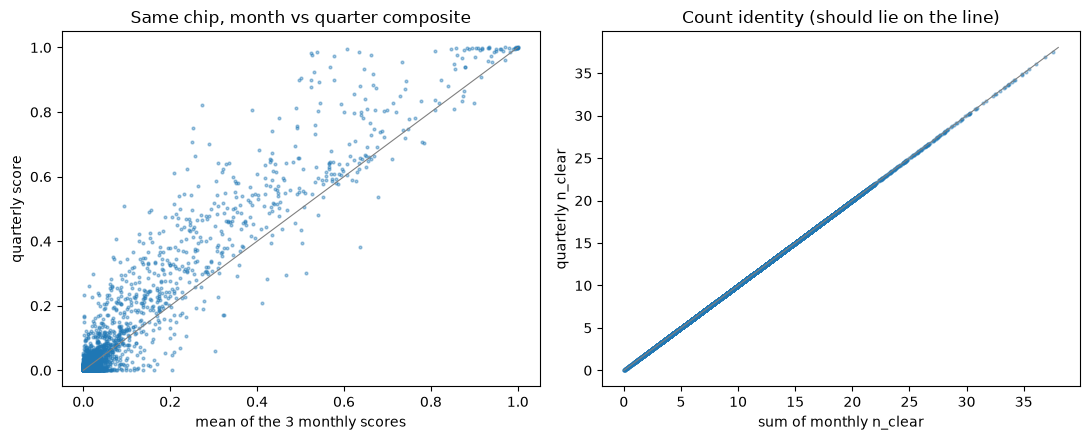

In [ ]:
if len(wide):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
    ax[0].scatter(full["conf_mean_m"], full["confidence"], s=4, alpha=0.4)
    ax[0].plot([0, 1], [0, 1], lw=0.8, color="grey")
    ax[0].set(xlabel="mean of the 3 monthly scores", ylabel="quarterly score",
              title="Same chip, month vs quarter composite")
    ax[1].scatter(full["n_clear_m"], full["n_clear"], s=4, alpha=0.4)
    lim = max(full["n_clear"].max(), full["n_clear_m"].max()) + 0.5
    ax[1].plot([0, lim], [0, lim], lw=0.8, color="grey")
    ax[1].set(xlabel="sum of monthly n_clear", ylabel="quarterly n_clear",
              title="Count identity (should lie on the line)")
    plt.tight_layout()

## 7. Combining runs

Different runs (another test area, the next region, a re-run) can be stacked because
`chip_id` comes from a fixed global grid. They are only **comparable** if they were scored the
same way, so the cell checks the model fingerprint and the settings that change a score before
stacking. Where two runs scored the same chip in the same period, both rows are kept with their
`run`, and the cell reports how far apart they are (Earth Engine data can change between runs,
especially for recent months).

In [ ]:
SCORE_SETTINGS = [("imagery", "collection"), ("imagery", "tilesize"), ("imagery", "pad"),
                  ("imagery", "clear_threshold"), ("inference", "stride_ratio")]

def comparable(runs: list[Path]) -> pd.DataFrame:
    rows = []
    for r in runs:
        cfg, prov = run_record(r)
        model = cfg["model"]["path"]
        row = {"run": run_label(r), "model_sha256": prov["file_sha256"].get(model, "?")[:12]}
        row |= {f"{a}.{b}": cfg[a][b] for a, b in SCORE_SETTINGS}
        rows.append(row)
    table = pd.DataFrame(rows).set_index("run")
    differ = [c for c in table.columns if table[c].nunique() > 1]
    print("comparable: same model and scoring settings" if not differ
          else f"NOT comparable, these differ: {differ}")
    return table

display(comparable(run_dirs))
if len(run_dirs) > 1:
    dup = long.groupby(["frequency", "period", "chip_id"])["run"].nunique()
    both = dup[dup > 1].index
    print(f"{len(both):,} (chip, period) scored by more than one run")
    if len(both):
        same = long.set_index(["frequency", "period", "chip_id"]).loc[both]
        spread = same.groupby(level=[0, 1, 2])["confidence"].agg(lambda s: s.max() - s.min())
        print(spread.describe())
else:
    print("Only one run listed in RUNS; add another run folder to see the overlap check.")

comparable: same model and scoring settings


,model_sha256,imagery.collection,imagery.tilesize,imagery.pad,imagery.clear_threshold,inference.stride_ratio
run,,,,,,
tests_output/test_region_2026-10-19,6d23c52bff24,S2L1C,552,12,0.6,2


Only one run listed in RUNS; add another run folder to see the overlap check.


## 8. A look at the data

Chip centres coloured by score, one period, monthly next to its quarter. Chips overlap by half,
so neighbouring points share pixels.

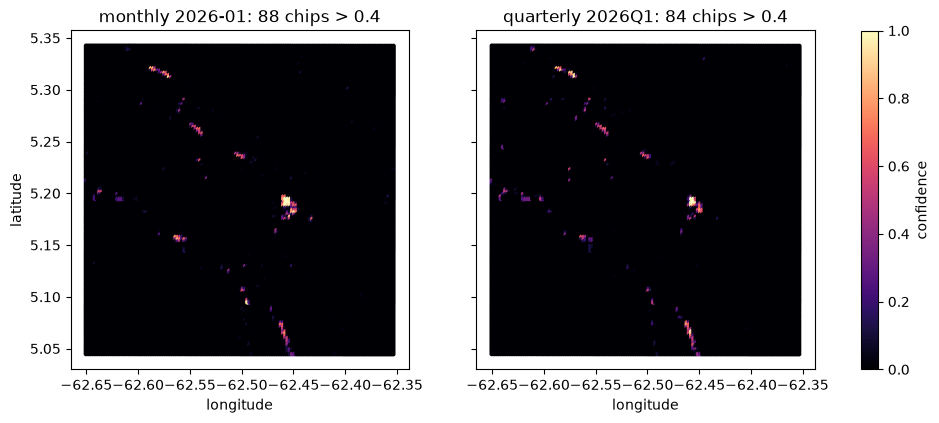

In [ ]:
r = run_dirs[0]
chips = load_chips(r, columns=["chip_id", "minx", "miny", "maxx", "maxy"])
chips["x"] = (chips["minx"] + chips["maxx"]) / 2
chips["y"] = (chips["miny"] + chips["maxy"]) / 2
mine = long[long["run"] == run_label(r)]
month = SHOW_PERIOD or sorted(mine.loc[mine["frequency"] == "monthly", "period"].unique())[0]
views = [("monthly", month), ("quarterly", _period(month).quarter().tag)]
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), sharex=True, sharey=True)
for ax, (freq, per) in zip(axes, views):
    sel = mine[(mine["frequency"] == freq) & (mine["period"] == per)].merge(chips, on="chip_id")
    if sel.empty:
        ax.set_title(f"{per}: not scored yet")
        continue
    sc = ax.scatter(sel["x"], sel["y"], c=sel["confidence"], s=6, cmap="magma", vmin=0, vmax=1)
    ax.set(title=f"{freq} {per}: {(sel['confidence'] > 0.4).sum()} chips > 0.4",
           xlabel="longitude", aspect="equal")
axes[0].set_ylabel("latitude")
fig.colorbar(sc, ax=axes, label="confidence", shrink=0.8)

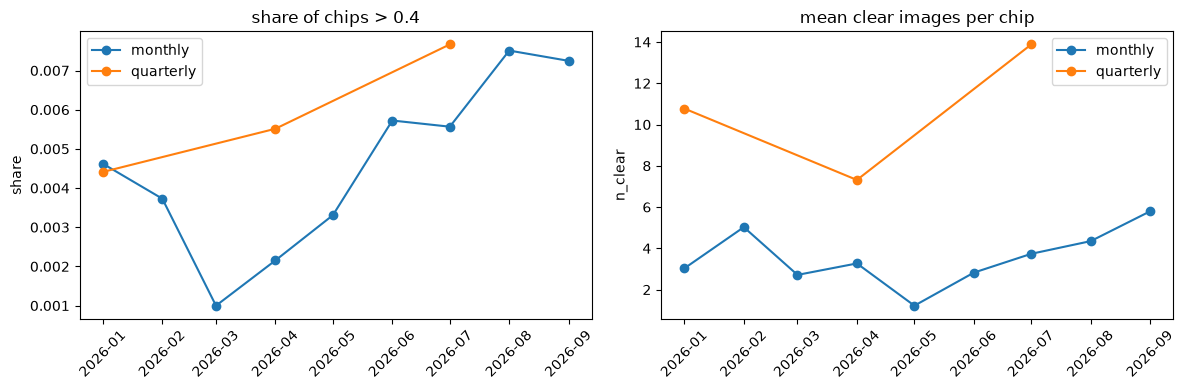

In [ ]:
ts = (long.assign(raw_det=long["confidence"] > 0.4)
          .groupby(["frequency", "period_start"])[["raw_det", "n_clear"]].mean().reset_index())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for freq, g in ts.groupby("frequency"):
    ax[0].plot(g["period_start"], g["raw_det"], marker="o", label=freq)
    ax[1].plot(g["period_start"], g["n_clear"], marker="o", label=freq)
ax[0].set(title="share of chips > 0.4", ylabel="share")
ax[1].set(title="mean clear images per chip", ylabel="n_clear")
for a in ax:
    a.legend(); a.tick_params(axis="x", rotation=45)
plt.tight_layout()

## 9. What the full Amazon run would weigh

Measured bytes per row in this run's part files, scaled to Amazon_ACA (about 145 million chips,
105 months + 35 quarters). Small files compress a little worse than big ones, so this errs high.

In [ ]:
parts = [p for r in run_dirs for p in (r / "detect").rglob("part_*.parquet")]
rows = sum(pq.ParquetFile(p).metadata.num_rows for p in parts)
size = sum(p.stat().st_size for p in parts)
bpr = size / rows
mem_row = long.memory_usage(deep=True).sum() / len(long)     # as loaded in section 5
CHIPS_ACA, MONTHS, QUARTERS, TILES_PER_SUB = 145e6, 105, 35, 274_932 / 6
print(f"measured: {rows:,} rows in {len(parts)} part files, {bpr:.1f} bytes per row on disk "
      f"(zstd), {mem_row:.0f} bytes per row in pandas")
for name, n in (("monthly", MONTHS), ("quarterly", QUARTERS)):
    print(f"{name:<10} {CHIPS_ACA * n / 1e9:5.1f} billion rows  ~{CHIPS_ACA * n * bpr / 1e9:6.0f} GB on disk  "
          f"~{CHIPS_ACA * mem_row / 1e9:.0f} GB in memory per period if loaded whole")
print(f"part files: ~{6 * (MONTHS + QUARTERS) * np.ceil(TILES_PER_SUB / 500):,.0f} "
      f"(840 task folders × ~92 batches of 500 tiles)")

measured: 228,528 rows in 12 part files, 45.6 bytes per row on disk (zstd), 154 bytes per row in pandas
monthly     15.2 billion rows  ~   694 GB on disk  ~22 GB in memory per period if loaded whole
quarterly    5.1 billion rows  ~   231 GB on disk  ~22 GB in memory per period if loaded whole
part files: ~77,280 (840 task folders × ~92 batches of 500 tiles)


**Reading the full panel later:** never `pd.read_parquet` the whole `detect/` folder. Filter
while reading, so only the needed files and columns leave the disk:

```python
d = detect_dataset(run, "monthly")
t = d.to_table(columns=["chip_id", "confidence", "n_clear"],
               filter=(ds.field("period") == "2024-07") & (ds.field("subregion") == 6))
```

The same works in DuckDB (`SELECT … FROM read_parquet('<run>/detect/monthly/*/*/*.parquet',
hive_partitioning=true) WHERE period = '2024-07'`) and in R with `arrow::open_dataset()`.